# BenthosAI — Satellite-Derived Bathymetry and Water Clarity from Sentinel-2

**Team:** BenthosAI · **Country:** United Arab Emirates · **Theme:** Water Quality & Inland/Coastal Water Intelligence

This notebook maps **water depth**, its **95 % uncertainty** and **water clarity / turbidity** for a coastal site in
Abu Dhabi (Jebel Dhanna) using only free, public data:

* **Sentinel-2 Level-2A** multispectral images (ESA Copernicus, via Microsoft Planetary Computer), and
* **NASA ICESat-2 ATL24** satellite-laser depths, used to calibrate and to test the image-based depth.

Workflow: load images → clean them (clouds, land, sun-glint) → water-quality layers (turbidity, optically-deep test)
→ depth features → calibrate three depth models on laser tracks → test them on **different, spatially separate**
laser tracks (two-fold cross-track validation) → fuse the three dates and attach a calibrated 95 % uncertainty → maps, tables and IHO S-44 grading.

Run all cells top to bottom (Kernel → Restart & Run All). Runtime is under one minute on a laptop, no GPU.
Inputs are read from `data/sample_input/`; outputs are written to `results/`.

## 0. Setup

In [1]:
import json, os, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
import matplotlib
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.linear_model import HuberRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Relative paths: works when started from the repository root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
INP, OUT = ROOT / "data" / "sample_input", ROOT / "results"
OUT.mkdir(exist_ok=True)

CFG = dict(
    SCL_CLOUD=[3, 8, 9, 10, 11],   # Sentinel-2 scene classes treated as cloud / shadow / cirrus / snow
    CLOUD_GROW_PX=5,               # grow the cloud mask by 50 m (cloud edges are under-detected)
    NDWI_MIN=0.0, SWIR_LAND_MAX=0.06,
    DEEP_SET_PCT=20, DEEP_REF_PCT=2,
    MIN_GLINT_R2=0.3,              # only remove sun-glint when B11 explains >= 30 % of deep-water variance
    SNR_MIN=3.0, NOISE_FLOOR=0.0005,
    NDTI_TURBID=0.05,              # normalised-difference turbidity index above this = turbid water
    LIDAR_MIN_PH=3, LIDAR_MIN_CONF=0.6, LIDAR_MAX_SPREAD=0.5, DEPTH_MIN=-0.5, DEPTH_MAX=12.0,
    TEST_TRACKS=["0006", "0448"],  # ICESat-2 tracks of fold A's test set (fold B swaps the roles)
    TEST_BUFFER_M=100,             # test pixels closer than this to any training pixel are dropped
    DEPTH_BANDS=[(-0.5, 2), (2, 5), (5, 12)],
)
print("Repository folder:", ROOT.name)
print("numpy", np.__version__, "| pandas", pd.__version__, "| rasterio", rasterio.__version__)

Repository folder: BenthosAI_SDB_PoC
numpy 2.1.3 | pandas 2.2.3 | rasterio 1.4.3


## 1. Input data

* `s2_scenes.json` lists the three Sentinel-2 scenes (IDs, dates, processing baseline). Each scene has a 10 m clip of
  the study area (`*_aoi10m.tif`, 4 × 5.8 km) and a 60 m clip of a wider 17 km box (`*_ctx60m.tif`) used to find
  open, deeper water as a reference.
* `icesat2_atl24_jebel_dhanna.csv`: ICESat-2 ATL24 bathymetry photons averaged into the same 10 m pixels. `depth_lat_m`
  is the depth below **lowest astronomical tide (LAT)** from the laser depth minus the tide at the pass time
  (global EOT20 tide model).

If the Sentinel-2 files are missing, set `DOWNLOAD_IF_MISSING = True`: the next cell then fetches the exact scenes
from Microsoft Planetary Computer (free, no account; needs the optional packages in `requirements.txt`).

In [2]:
DOWNLOAD_IF_MISSING = False
if not (INP / "s2_scenes.json").exists():
    if DOWNLOAD_IF_MISSING:
        import runpy; runpy.run_path(str(ROOT / "scripts" / "download_sample.py"), run_name="__main__")
    else:
        raise FileNotFoundError("Sentinel-2 sample missing: run `python scripts/download_sample.py` or set DOWNLOAD_IF_MISSING = True")

S2META = json.loads((INP / "s2_scenes.json").read_text())
BANDS = S2META["bands"]
lidar_raw = pd.read_csv(INP / "icesat2_atl24_jebel_dhanna.csv")
pd.DataFrame(S2META["scenes"])[["id", "date", "processing_baseline", "sun_zenith_deg", "cloud_cover_pct"]]

,id,date,processing_baseline,sun_zenith_deg,cloud_cover_pct
0,S2A_MSIL2A_20220829T065641_R063_T39QXG_2024071...,2022-08-29,05.10,23.588369,0.187113
1,S2B_MSIL2A_20220903T065629_R063_T39QXG_2022090...,2022-09-03,04.00,24.552078,0.258712
2,S2B_MSIL2A_20220923T065629_R063_T39QXG_2024072...,2022-09-23,05.10,29.311237,0.718654


## 2. Image preparation

For each date:

1. **Digital numbers → reflectance**: `(DN − 1000) / 10000` for processing baseline ≥ 4.0 (ESA's offset), else `DN / 10000`.
2. **Clouds**: Sentinel-2 scene classification (SCL) cloud, shadow and cirrus classes, grown by 50 m.
3. **Water**: NDWI = (green − NIR) / (green + NIR) > 0 **and** dark short-wave infrared (B11 < 0.06). Land, quays and ships are bright in B11.
4. **Deep-water reference**: the darkest 20 % of water in the 17 km context box. Its reflectance (`ρ∞`) is what
   water looks like when the seabed is invisible.
5. **Sun-glint** (Hedley et al. 2005): over deep water, variation in B11 is surface glint. If a band follows B11
   (R² ≥ 0.3), the glint part `β · (B11 − min B11)` is subtracted.
6. **Can the seabed be seen?** Signal-to-noise `(green − ρ∞) / noise`. Below 3, the pixel is *optically deep*: no depth is given.
7. **Water quality**: NDTI = (red − green) / (red + green), a standard turbidity index (Lacaux et al. 2007), and the
   red-edge B05 signal above deep water (suspended sediment raises it). NDTI > 0.05 = turbid.

In [3]:
def read_clip(path):
    with rasterio.open(path) as src:
        arr = src.read().astype("float32")
        prof = src.profile
    return {b: arr[i] for i, b in enumerate(BANDS)}, prof

def to_reflectance(d, baseline):
    off = 1000.0 if float(baseline or 0) >= 4.0 else 0.0
    out = {}
    for b in BANDS:
        if b == "SCL":
            out[b] = d[b].astype("uint8")
        else:
            v = (d[b] - off) / 10000.0
            out[b] = np.where(d[b] > 0, v, np.nan).astype("float32")
    return out

def masks(r, grow):
    cloud = np.isin(r["SCL"], CFG["SCL_CLOUD"])
    if grow:
        cloud = ndimage.binary_dilation(cloud, iterations=grow)
    with np.errstate(invalid="ignore", divide="ignore"):
        ndwi = (r["B03"] - r["B08"]) / (r["B03"] + r["B08"])
    water = (ndwi > CFG["NDWI_MIN"]) & (r["B11"] < CFG["SWIR_LAND_MAX"]) & ~cloud & np.isfinite(r["B03"])
    return water, cloud

def prepare_scene(meta):
    a_raw, prof = read_clip(INP / meta["aoi_file"])
    c_raw, _ = read_clip(INP / meta["ctx_file"])
    A, C = to_reflectance(a_raw, meta["processing_baseline"]), to_reflectance(c_raw, meta["processing_baseline"])
    wA, cloudA = masks(A, CFG["CLOUD_GROW_PX"])
    wC, _ = masks(C, 0)
    g = C["B03"][wC]
    deep = wC & (C["B03"] <= np.nanpercentile(g, CFG["DEEP_SET_PCT"]))
    # sun-glint removal against B11
    b11min = np.nanmin(C["B11"][deep])
    glint = {}
    for b in ["B01", "B02", "B03", "B04", "B05", "B08"]:
        x, y = C["B11"][deep], C[b][deep]
        ok = np.isfinite(x) & np.isfinite(y)
        r2, beta = 0.0, 0.0
        if ok.sum() > 50 and np.nanstd(x[ok]) > 0:
            beta, a0 = np.polyfit(x[ok], y[ok], 1)
            r2 = np.corrcoef(x[ok], y[ok])[0, 1] ** 2
        if r2 >= CFG["MIN_GLINT_R2"] and beta > 0:
            A[b] = A[b] - beta * (A["B11"] - b11min); C[b] = C[b] - beta * (C["B11"] - b11min)
        glint[b] = round(float(r2), 3)
    ref = wC & (C["B03"] <= np.nanpercentile(C["B03"][wC], CFG["DEEP_REF_PCT"]))
    rho_inf = {b: float(np.nanmedian(C[b][ref])) for b in ["B01", "B02", "B03", "B04", "B05"]}
    gd = C["B03"][deep]
    noise = max(CFG["NOISE_FLOOR"], 1.4826 * float(np.nanmedian(np.abs(gd - np.nanmedian(gd)))))
    with np.errstate(invalid="ignore", divide="ignore"):
        snr = (A["B03"] - rho_inf["B03"]) / noise
        ndti = (A["B04"] - A["B03"]) / (A["B04"] + A["B03"])
    seabed_visible = wA & (snr >= CFG["SNR_MIN"])
    turbid = wA & (ndti > CFG["NDTI_TURBID"])
    return dict(meta=meta, R=A, prof=prof, water=wA, cloud=cloudA, visible=seabed_visible, turbid=turbid,
                snr=snr, ndti=np.where(wA, ndti, np.nan), b05_turb=np.where(wA, A["B05"] - rho_inf["B05"], np.nan),
                rho_inf=rho_inf, noise=noise, glint_r2=glint)

scenes = [prepare_scene(m) for m in S2META["scenes"]]
H, W = scenes[0]["water"].shape
PROF = scenes[0]["prof"]
qa = pd.DataFrame([dict(date=s["meta"]["date"], water_pct=100 * s["water"].mean(), cloud_pct=100 * s["cloud"].mean(),
                        seabed_visible_pct_of_water=100 * s["visible"].sum() / max(s["water"].sum(), 1),
                        turbid_pct_of_water=100 * s["turbid"].sum() / max(s["water"].sum(), 1),
                        noise=s["noise"], glint_r2_B02=s["glint_r2"]["B02"]) for s in scenes]).round(3)
qa

,date,water_pct,cloud_pct,seabed_visible_pct_of_water,turbid_pct_of_water,noise,glint_r2_B02
0,2022-08-29,96.019,1.164,99.115,0.000,0.002,0.156
1,2022-09-03,97.057,0.827,95.529,0.000,0.003,0.009
2,2022-09-23,92.511,1.188,97.258,0.607,0.002,0.239


## 3. Depth features

Light reflected from a shallow seabed fades with depth, and blue light fades more slowly than green. Two classical
features capture this:

* **Stumpf log-ratio** (Stumpf et al. 2003): `pSDB = ln(1000·R_blue) / ln(1000·R_green)`; it grows with depth and is
  robust to changes in seabed brightness.
* **Lyzenga linear features** (Lyzenga 1978): `X_i = ln(R_i − ρ∞,i)` for bands B01–B04; depth is close to a linear
  combination of them.

The machine-learning model also sees the red-edge band and the turbidity index, so it can learn where colour stops
following depth.

In [4]:
FEATS = ["pSDB", "X_B01", "X_B02", "X_B03", "X_B04", "b05_turb", "ndti"]

def features(s):
    R, ri = s["R"], s["rho_inf"]
    with np.errstate(invalid="ignore", divide="ignore"):
        F = {"pSDB": np.log(1000 * np.clip(R["B02"], 1e-4, None)) / np.log(1000 * np.clip(R["B03"], 1e-4, None))}
        for b in ["B01", "B02", "B03", "B04"]:
            F[f"X_{b}"] = np.log(np.clip(R[b] - ri[b], 1e-4, None))
    F["b05_turb"], F["ndti"] = s["b05_turb"], s["ndti"]
    return F

for s in scenes:
    s["F"] = features(s)
print("Features per scene:", FEATS)

Features per scene: ['pSDB', 'X_B01', 'X_B02', 'X_B03', 'X_B04', 'b05_turb', 'ndti']


## 4. ICESat-2 laser depths: quality control and a leak-free, cross-track split

Laser pixels are kept if they have ≥ 3 bathymetry photons, mean confidence ≥ 0.6 and a vertical spread ≤ 0.5 m.

**Why we split by track.** ICESat-2 revisits the same *reference ground track* (RGT) every 91 days, so passes on the
same track sample the same pixels. Splitting by date would leak neighbouring pixels between training and test.
Three tracks cross the site: RGT **1218** (five passes 2019–2023) and RGTs **0006** and **0448** (2021).

**Two-fold cross-track validation:**
- fold A trains on track 1218 and tests on 0006 + 0448;
- fold B trains on 0006 + 0448 and tests on 1218.

Test pixels within 100 m of any training pixel are removed. Every laser pixel is predicted once, by models that
never saw its track. The final map is then trained on all tracks.

In [5]:
L = lidar_raw.copy()
L["rgt"] = L.granule.str.slice(21, 25)
L = L[(L.n_photons >= CFG["LIDAR_MIN_PH"]) & (L.confidence >= CFG["LIDAR_MIN_CONF"]) &
      (L.h_spread_m <= CFG["LIDAR_MAX_SPREAD"]) & L.depth_lat_m.between(CFG["DEPTH_MIN"], CFG["DEPTH_MAX"])].copy()
tr = PROF["transform"]
L["col"] = ((L.x_utm39n - tr.c) / tr.a).astype(int)
L["row"] = ((L.y_utm39n - tr.f) / tr.e).astype(int)
L = L[L.col.between(0, W - 1) & L.row.between(0, H - 1)]
L["pair"] = L.beam.str.slice(0, 3)
# one value per pixel and track (median over passes on the same track)
P = (L.groupby(["rgt", "row", "col"]).agg(depth=("depth_lat_m", "median"), x=("x_utm39n", "first"),
                                          y=("y_utm39n", "first"), pair=("pair", "first"),
                                          n_pass=("granule", "nunique")).reset_index())
from scipy.spatial import cKDTree
FOLDS = {"A": (["1218"], CFG["TEST_TRACKS"]), "B": (CFG["TEST_TRACKS"], ["1218"])}
def split(train_tracks, test_tracks):
    trn = P[P.rgt.isin(train_tracks)].reset_index(drop=True)
    tst = P[P.rgt.isin(test_tracks)].reset_index(drop=True)
    d, _ = cKDTree(trn[["x", "y"]].values).query(tst[["x", "y"]].values)
    return trn, tst[d > CFG["TEST_BUFFER_M"]].reset_index(drop=True)
print(P.groupby("rgt").agg(pixels=("depth", "size"), passes=("n_pass", "max"), depth_min=("depth", "min"),
                           depth_median=("depth", "median"), depth_max=("depth", "max")).round(2))
for f, (a, b) in FOLDS.items():
    trn, tst = split(a, b)
    print(f"fold {f}: train tracks {a} ({len(trn)} px) -> test tracks {b} ({len(tst)} px after the 100 m buffer)")

      pixels  passes  depth_min  depth_median  depth_max
rgt                                                     
0006     197       1      -0.15          4.77       9.02
0448      13       1       0.11          7.07       8.21
1218     582       2      -0.23          0.68       8.07
fold A: train tracks ['1218'] (582 px) -> test tracks ['0006', '0448'] (210 px after the 100 m buffer)
fold B: train tracks ['0006', '0448'] (210 px) -> test tracks ['1218'] (582 px after the 100 m buffer)


## 5. Depth models, calibrated per image date

For every date we fit three models on the training pixels that are clear water with a visible seabed:

| Model | What it is |
|---|---|
| **Stumpf** (baseline) | robust straight line `depth = m1·pSDB + m0` (Huber loss) |
| **Lyzenga** | robust multiple linear regression on X_B01–X_B04 |
| **Gradient boosting** | `HistGradientBoostingRegressor` on all seven features, with depth-balanced sample weights so shallow and deeper water count equally |

Fitting each date separately absorbs that date's water level (tide at the image time), atmosphere and water colour.
The three dates are then fused, each weighted by its out-of-sample error (leave one ICESat-2 beam pair out).

In [6]:
METHODS = ["Stumpf", "Lyzenga", "Gradient boosting"]

def depth_weights(y):
    bins = np.digitize(y, [2, 5])
    cnt = np.bincount(bins, minlength=3).astype(float)
    return np.minimum((len(y) / (3 * np.maximum(cnt, 1)))[bins], 5.0)

def make_model(name):
    if name == "Stumpf":
        return HuberRegressor(max_iter=500), [0]
    if name == "Lyzenga":
        return HuberRegressor(max_iter=500), [1, 2, 3, 4]
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=10,
                                         l2_regularization=1.0, random_state=SEED), list(range(len(FEATS)))

def feats_at(s, rows, cols):
    return np.column_stack([s["F"][f][rows, cols] for f in FEATS])

def fit_one(s, df, name):
    X = feats_at(s, df.row.values, df.col.values)
    ok = np.isfinite(X).all(1) & s["visible"][df.row.values, df.col.values] & ~s["cloud"][df.row.values, df.col.values]
    m, cols = make_model(name)
    y = df.depth.values[ok]
    m.fit(X[ok][:, cols], y, sample_weight=depth_weights(y))
    return m, cols

def predict_one(s, m, cols, rows, cc_):
    X = feats_at(s, rows, cc_)
    out = np.full(len(rows), np.nan)
    good = np.isfinite(X).all(1)
    out[good] = m.predict(X[good][:, cols])
    return out

def fuse_stack(S, w):
    S = np.asarray(S); w = np.asarray(w)[:, None] * np.isfinite(S)
    ws = w.sum(0)
    mu = np.where(ws > 0, np.nansum(S * w, 0) / np.where(ws > 0, ws, 1), np.nan)
    var = np.where(ws > 0, np.nansum(w * (S - mu) ** 2, 0) / np.where(ws > 0, ws, 1), np.nan)
    return mu, np.sqrt(var)

def train_and_predict(trn, rows, cols_):
    # Fit per scene and method on `trn`; return fused prediction and between-date spread at (rows, cols_),
    # plus leave-beam-pair-out fused predictions on the training pixels.
    out = {}
    for name in METHODS:
        preds, oofs = [], []
        for s in scenes:
            m, c = fit_one(s, trn, name)
            preds.append(predict_one(s, m, c, rows, cols_))
            o = np.full(len(trn), np.nan)
            for g in sorted(trn.pair.unique()):
                a, b = trn[trn.pair != g], trn[trn.pair == g]
                if len(a) >= 30 and len(b):
                    mg, cg = fit_one(s, a, name)
                    o[b.index.values] = predict_one(s, mg, cg, b.row.values, b.col.values)
            oofs.append(o)
        w = 1.0 / np.maximum([np.nanmean((o - trn.depth.values) ** 2) for o in oofs], 1e-3)
        mu, sd = fuse_stack(preds, w)
        omu, osd = fuse_stack(oofs, w)
        out[name] = dict(mu=mu, sd=sd, oof_mu=omu, oof_sd=osd, w=w)
    return out
print("Model functions ready:", METHODS)

Model functions ready: ['Stumpf', 'Lyzenga', 'Gradient boosting']


## 6. Cross-track validation and a calibrated 95 % uncertainty

**U95 (conformal).** For each pixel, `U95 = q_band · (σ + γ)`:
- σ is the spread between the three dates;
- γ is the median σ;
- `q_band` is the 95th percentile of `|error| / (σ + γ)` per depth band.

This is split-conformal prediction (Vovk et al. 2005). Inside each fold, q is learned from the training tracks only,
then checked on the test track. For the final map, q is learned from the cross-track errors of both folds, so the
map's uncertainty reflects errors on *unseen* tracks.

Accuracy is reported for every laser pixel predicted from the *other* tracks:
- RMSE, MAE, bias and R²;
- error by depth band;
- U95 coverage;
- the share inside the **IHO S-44 (6th ed.)** vertical uncertainty `TVU = √(a² + (b·d)²)`, for Special Order
  (a = 0.25 m, b = 0.0075), Order 1a/1b (0.5 m, 0.013) and Order 2 (1.0 m, 0.023).

In [7]:
S44 = {"Special": (0.25, 0.0075), "Order 1a/1b": (0.5, 0.013), "Order 2": (1.0, 0.023)}
NB = len(CFG["DEPTH_BANDS"])
band_of = lambda d: np.clip(np.digitize(d, [b[1] for b in CFG["DEPTH_BANDS"][:-1]]), 0, NB - 1)

def conformal_q(err, sd, gamma, pred):
    sc = np.abs(err) / (sd + gamma)
    q = {}
    for b in range(NB):
        x = sc[(band_of(pred) == b) & np.isfinite(sc)]
        n = len(x)
        q[b] = float(np.quantile(x, min(1.0, np.ceil((n + 1) * 0.95) / n))) if n >= 20 else float(np.nanquantile(sc, 0.95))
    return q

def metrics(pred, ref, u95=None):
    ok = np.isfinite(pred) & np.isfinite(ref)
    p, r = pred[ok], ref[ok]; e = p - r
    out = dict(n=int(ok.sum()), RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)), bias=np.mean(e),
               R2=1 - np.sum(e ** 2) / np.sum((r - r.mean()) ** 2) if ok.sum() > 2 else np.nan)
    for k, (a, b) in S44.items():
        out[f"S-44 {k} %"] = 100 * np.mean(np.abs(e) <= np.sqrt(a ** 2 + (b * np.abs(r)) ** 2))
    if u95 is not None:
        out["U95 coverage %"] = 100 * np.mean(np.abs(e) <= u95[ok]); out["median U95 m"] = np.median(u95[ok])
    return out

cv = []
for f, (a, b) in FOLDS.items():
    trn, tst = split(a, b)
    res = train_and_predict(trn, tst.row.values, tst.col.values)
    for name in METHODS:
        r = res[name]
        gamma = max(float(np.nanmedian(r["oof_sd"])), 0.05)
        q = conformal_q(r["oof_mu"] - trn.depth.values, r["oof_sd"], gamma, r["oof_mu"])
        u95 = np.array([q[k] for k in range(NB)])[band_of(np.nan_to_num(r["mu"]))] * (r["sd"] + gamma)
        cv.append(pd.DataFrame(dict(fold=f, method=name, rgt=tst.rgt, row=tst.row, col=tst.col, ref=tst.depth,
                                    pred=r["mu"], sd=r["sd"], u95=np.where(np.isfinite(r["mu"]), u95, np.nan))))
CV = pd.concat(cv, ignore_index=True)

rows, band_rows, fold_rows = [], [], []
for name in METHODS:
    d = CV[CV.method == name]
    rows.append(dict(method=name, **metrics(d.pred.values, d.ref.values, d.u95.values)))
    for f in FOLDS:
        dd = d[d.fold == f]
        fold_rows.append(dict(method=name, fold=f, test_tracks=",".join(FOLDS[f][1]), **metrics(dd.pred.values, dd.ref.values, dd.u95.values)))
    for bi, (lo, hi) in enumerate(CFG["DEPTH_BANDS"]):
        dd = d[(d.ref >= lo) & (d.ref < hi)]
        band_rows.append(dict(method=name, depth_band=f"{max(lo, 0):g}–{hi:g} m", **metrics(dd.pred.values, dd.ref.values, dd.u95.values)))
M = pd.DataFrame(rows).set_index("method").round(3)
MB = pd.DataFrame(band_rows).round(3); MF = pd.DataFrame(fold_rows).round(3)
M.to_csv(OUT / "metrics_cross_track.csv"); MB.to_csv(OUT / "metrics_by_depth_band.csv", index=False)
MF.to_csv(OUT / "metrics_by_fold.csv", index=False)
print(f"Cross-track test pixels: {CV[CV.method == METHODS[0]].shape[0]} (every laser pixel, predicted from the other tracks)")
M

Cross-track test pixels: 792 (every laser pixel, predicted from the other tracks)


,n,RMSE,MAE,bias,R2,S-44 Special %,S-44 Order 1a/1b %,S-44 Order 2 %,U95 coverage %,median U95 m
method,,,,,,,,,,
Stumpf,789,1.246,0.996,0.275,0.731,14.956,29.278,58.809,98.733,4.051
Lyzenga,789,1.005,0.860,-0.522,0.825,11.027,24.715,67.174,90.241,1.934
Gradient boosting,789,0.669,0.425,-0.061,0.922,55.767,74.398,86.185,97.085,1.184


In [8]:
display(MF[["method", "fold", "test_tracks", "n", "RMSE", "bias", "R2", "S-44 Order 2 %", "U95 coverage %"]])
MB.pivot(index="depth_band", columns="method", values="RMSE")

,method,fold,test_tracks,n,RMSE,bias,R2,S-44 Order 2 %,U95 coverage %
0,Stumpf,A,"0006,0448",207,1.630,-0.789,0.638,44.444,98.551
1,Stumpf,B,1218,582,1.077,0.653,0.422,63.918,98.797
2,Lyzenga,A,"0006,0448",207,1.362,-0.262,0.747,44.444,64.251
3,Lyzenga,B,1218,582,0.842,-0.614,0.647,75.258,99.485
4,Gradient boosting,A,"0006,0448",207,1.115,-0.279,0.831,62.802,91.787
5,Gradient boosting,B,1218,582,0.406,0.017,0.918,94.502,98.969


method,Gradient boosting,Lyzenga,Stumpf
depth_band,,,
0–2 m,0.202,0.789,1.192
2–5 m,0.770,1.025,0.746
5–12 m,1.291,1.542,2.038


## 7. Final maps from all tracks

The final models are fitted on **all** laser pixels, and the three dates are fused. The U95 scale `q_band` comes
from the cross-track errors above.

**Flags:**
- 1 = valid;
- 2 = optically deep (seabed not visible on most dates);
- 3 = valid but turbid;
- 4 = land or cloud.

In [9]:
BEST = M["RMSE"].idxmin()
rr, cc = np.indices((H, W))
final = train_and_predict(P.assign(pair=P.pair).reset_index(drop=True), rr.ravel(), cc.ravel())
visible_frac = np.mean([s["visible"] for s in scenes], 0)
turbid_frac = np.mean([s["turbid"] for s in scenes], 0)
water_any = np.any([s["water"] & ~s["cloud"] for s in scenes], 0)
flag = np.full((H, W), 4, np.uint8)
flag[water_any] = 2
flag[water_any & (visible_frac >= 0.5)] = 1
flag[(flag == 1) & (turbid_frac > 0.5)] = 3
products = {}
for name in METHODS:
    f = final[name]
    depth = f["mu"].reshape(H, W); sigma = f["sd"].reshape(H, W)
    gamma = max(float(np.nanmedian(sigma[np.isin(flag, [1, 3])])), 0.05)
    d = CV[CV.method == name]
    q = conformal_q(d.pred.values - d.ref.values, d.sd.values, gamma, d.pred.values)
    u95 = np.array([q[k] for k in range(NB)])[band_of(np.nan_to_num(depth))] * (sigma + gamma)
    keep = np.isin(flag, [1, 3]) & np.isfinite(depth)
    products[name] = dict(depth=np.where(keep, depth, np.nan), u95=np.where(keep, u95, np.nan), q=q, gamma=gamma)
print("Best method (lowest cross-track RMSE):", BEST)
print({k: {"q_by_band": {str(CFG['DEPTH_BANDS'][b]): round(v, 2) for b, v in p["q"].items()}, "gamma": round(p["gamma"], 3)} for k, p in products.items()})

Best method (lowest cross-track RMSE): Gradient boosting
{'Stumpf': {'q_by_band': {'(-0.5, 2)': 0.66, '(2, 5)': 1.39, '(5, 12)': 1.33}, 'gamma': 0.897}, 'Lyzenga': {'q_by_band': {'(-0.5, 2)': 2.03, '(2, 5)': 2.43, '(5, 12)': 3.49}, 'gamma': 0.427}, 'Gradient boosting': {'q_by_band': {'(-0.5, 2)': 0.58, '(2, 5)': 1.76, '(5, 12)': 2.52}, 'gamma': 0.426}}


## 8. Outputs: maps, figures and a GeoTIFF

- `results/example_output.png`: true colour, depth, 95 % uncertainty and turbidity, with the ICESat-2 tracks.
- `results/validation_scatter.png`: predicted vs laser depth, cross-track (each pixel predicted from the other tracks).
- `results/depth_uncertainty_turbidity.tif`: 4-band GeoTIFF (depth below LAT, U95, NDTI, flag), EPSG:32639, 10 m.
- `results/water_quality_summary.csv` and `results/run_summary.json`.

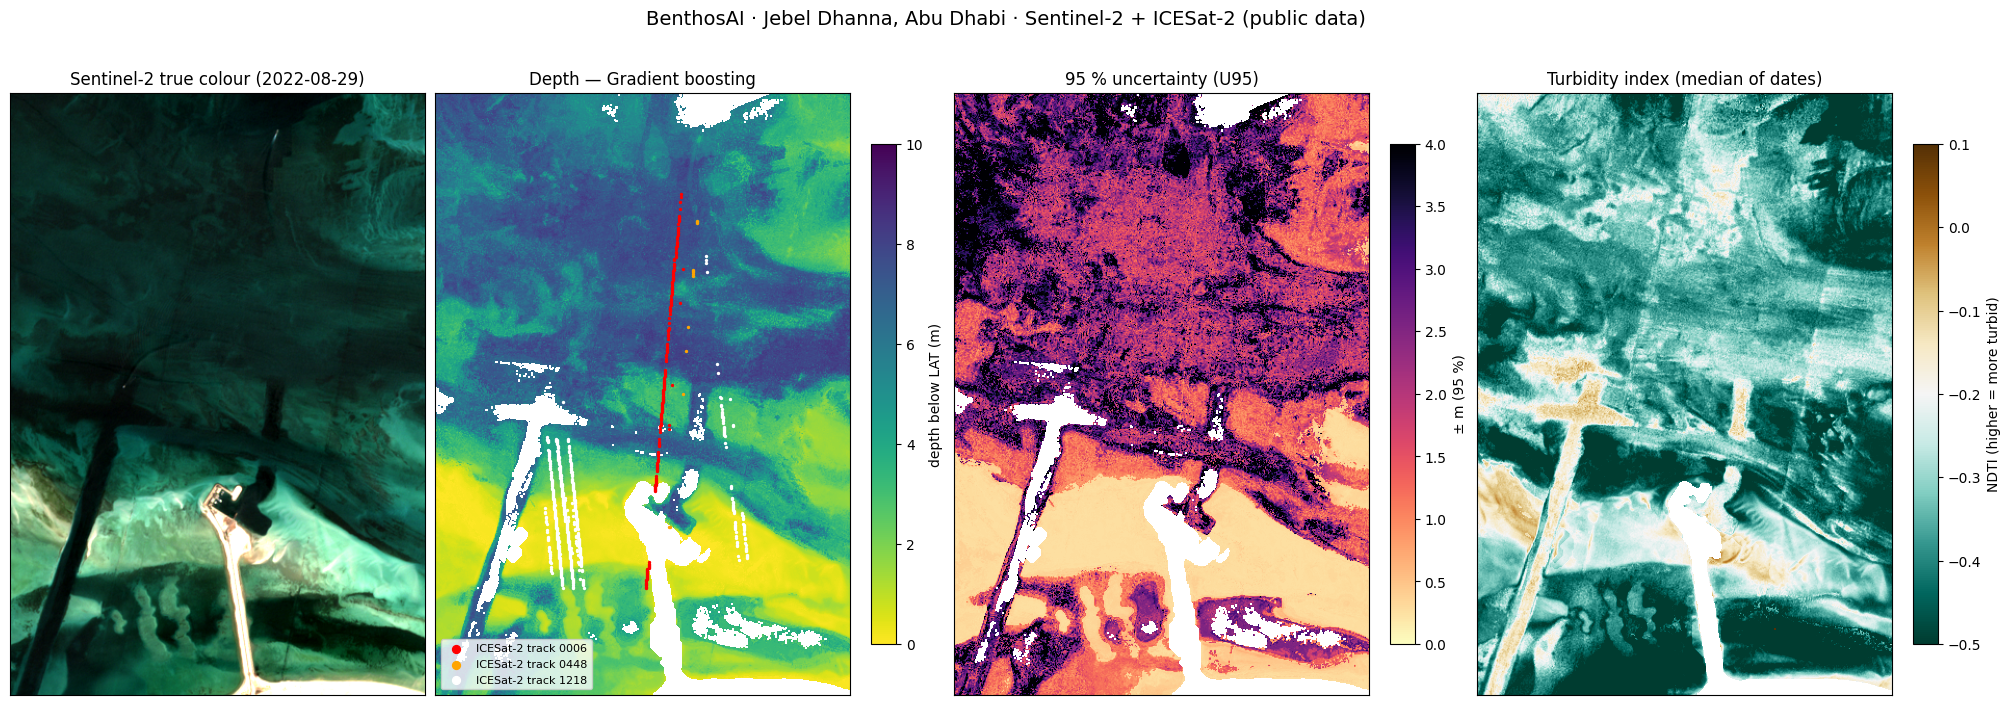

In [10]:
prod = products[BEST]
s0 = max(scenes, key=lambda s: np.isfinite(s["R"]["B02"]).mean())
rgb = np.dstack([s0["R"][b] for b in ["B04", "B03", "B02"]])
lo, hi = np.nanpercentile(rgb, 2), np.nanpercentile(rgb, 98)
rgb = np.nan_to_num(np.clip((rgb - lo) / (hi - lo), 0, 1))
ndti_med = np.nanmedian(np.stack([s["ndti"] for s in scenes]), 0)
ext = [tr.c, tr.c + tr.a * W, tr.f + tr.e * H, tr.f]
colors = {"1218": "white", "0006": "red", "0448": "orange"}

fig, ax = plt.subplots(1, 4, figsize=(20, 7.5), constrained_layout=True)
ax[0].imshow(rgb, extent=ext); ax[0].set_title(f"Sentinel-2 true colour ({s0['meta']['date']})")
im = ax[1].imshow(prod["depth"], extent=ext, cmap="viridis_r", vmin=0, vmax=10)
fig.colorbar(im, ax=ax[1], shrink=0.7, label="depth below LAT (m)"); ax[1].set_title(f"Depth — {BEST}")
im = ax[2].imshow(prod["u95"], extent=ext, cmap="magma_r", vmin=0, vmax=4)
fig.colorbar(im, ax=ax[2], shrink=0.7, label="± m (95 %)"); ax[2].set_title("95 % uncertainty (U95)")
im = ax[3].imshow(np.where(water_any, ndti_med, np.nan), extent=ext, cmap="BrBG_r", vmin=-0.5, vmax=0.1)
fig.colorbar(im, ax=ax[3], shrink=0.7, label="NDTI (higher = more turbid)"); ax[3].set_title("Turbidity index (median of dates)")
for g, d in P.groupby("rgt"):
    ax[1].scatter(d.x, d.y, s=2, c=colors.get(g, "cyan"), label=f"ICESat-2 track {g}")
ax[1].legend(loc="lower left", fontsize=8, markerscale=4)
for a in ax:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("BenthosAI · Jebel Dhanna, Abu Dhabi · Sentinel-2 + ICESat-2 (public data)", fontsize=14)
fig.savefig(OUT / "example_output.png", dpi=110)
plt.show()

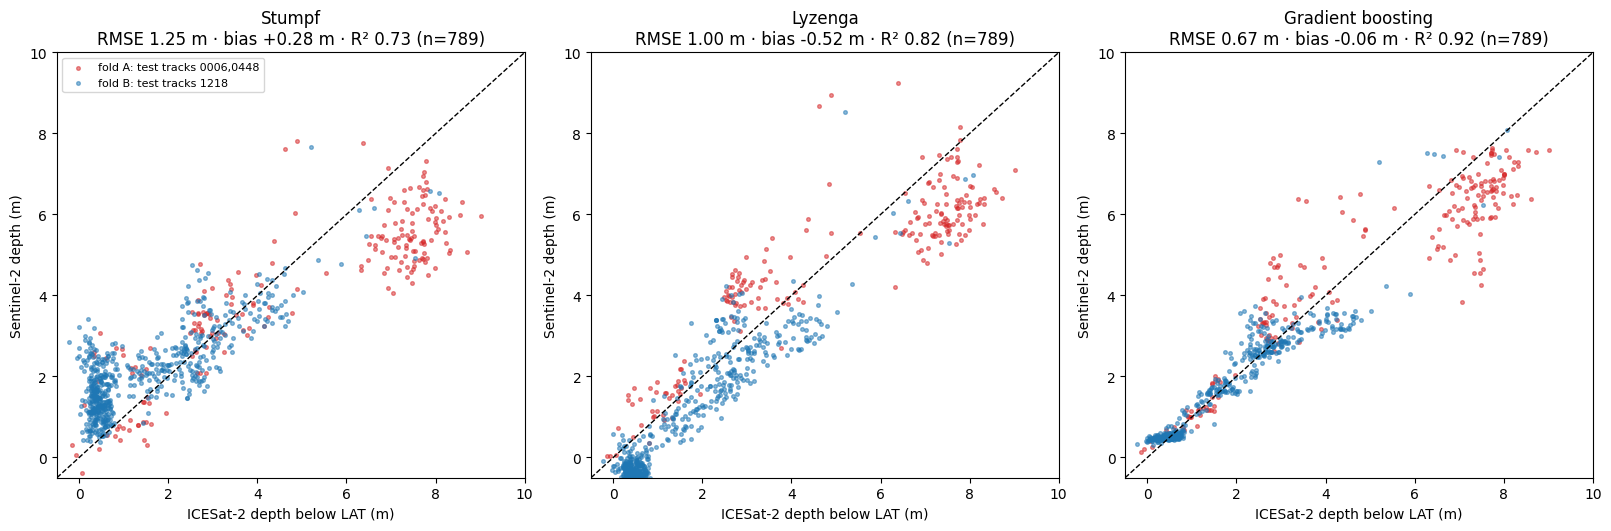

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
for a, name in zip(ax, METHODS):
    d = CV[CV.method == name]
    for f, c in [("A", "tab:red"), ("B", "tab:blue")]:
        dd = d[d.fold == f]
        a.scatter(dd.ref, dd.pred, s=7, alpha=0.5, c=c, label=f"fold {f}: test tracks {','.join(FOLDS[f][1])}")
    lim = [-0.5, 10]
    a.plot(lim, lim, "k--", lw=1); a.set_xlim(lim); a.set_ylim(lim)
    r = M.loc[name]
    a.set_title(f"{name}\nRMSE {r.RMSE:.2f} m · bias {r.bias:+.2f} m · R² {r.R2:.2f} (n={int(r.n)})")
    a.set_xlabel("ICESat-2 depth below LAT (m)"); a.set_ylabel("Sentinel-2 depth (m)")
ax[0].legend(fontsize=8, loc="upper left")
fig.savefig(OUT / "validation_scatter.png", dpi=110)
plt.show()

In [12]:
prof = PROF.copy(); prof.update(count=4, dtype="float32", nodata=np.nan, compress="deflate", predictor=3)
with rasterio.open(OUT / "depth_uncertainty_turbidity.tif", "w", **prof) as dst:
    dst.write(np.stack([prod["depth"], prod["u95"], np.where(water_any, ndti_med, np.nan), flag.astype("float32")]).astype("float32"))
    for i, d in enumerate(["depth_below_LAT_m", "U95_m", "NDTI", "flag_1valid_2deep_3turbid_4land"], 1):
        dst.set_band_description(i, d)

wq = pd.DataFrame([dict(date=s["meta"]["date"], median_NDTI=float(np.nanmedian(s["ndti"])),
                        turbid_pct_of_water=100 * s["turbid"].sum() / max(s["water"].sum(), 1),
                        seabed_visible_pct_of_water=100 * s["visible"].sum() / max(s["water"].sum(), 1),
                        red_edge_turbidity=float(np.nanmedian(s["b05_turb"]))) for s in scenes]).round(4)
wq.to_csv(OUT / "water_quality_summary.csv", index=False)
summary = dict(site="Jebel Dhanna, Abu Dhabi, UAE", crs="EPSG:32639", scenes=[s["meta"]["id"] for s in scenes],
               best_method=BEST, validation="2-fold cross-track (ICESat-2 RGT 1218 vs RGTs 0006+0448, 100 m buffer)",
               cv_pixels=int(M.loc[BEST, "n"]), metrics_cross_track=M.reset_index().to_dict(orient="records"),
               metrics_by_fold=MF.to_dict(orient="records"),
               mapped_pct_of_clear_water=float(100 * np.isfinite(prod["depth"]).sum() / max(water_any.sum(), 1)), seed=SEED)
(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("Files in results/:", sorted(p.name for p in OUT.iterdir()))
wq

Files in results/: ['depth_uncertainty_turbidity.tif', 'example_output.png', 'metrics_by_depth_band.csv', 'metrics_by_fold.csv', 'metrics_cross_track.csv', 'run_summary.json', 'validation_scatter.png', 'water_quality_summary.csv']


,date,median_NDTI,turbid_pct_of_water,seabed_visible_pct_of_water,red_edge_turbidity
0,2022-08-29,-0.2874,0.0000,99.1148,0.0238
1,2022-09-03,-0.3775,0.0000,95.5292,0.0189
2,2022-09-23,-0.4299,0.6066,97.2580,0.0229


## 9. What this shows, and its limits

* The pipeline produces a dated depth map with a per-pixel 95 % uncertainty and a turbidity layer from free data,
  in minutes, for any clear coastal water where ICESat-2 has passed.
* The results table above compares the classical Stumpf baseline with Lyzenga and gradient boosting on laser tracks
  the models never saw.

**Limitations.**

* **Depth reach.** Optical depth mapping only works where the seabed is visible: in clear Gulf water to about 10–12 m,
  less in turbid water. Deeper or turbid pixels are flagged, not guessed.
* **Time gap.** The laser passes span 2019–2023 and the images are from Aug–Sep 2022. Jebel Dhanna has dredged areas,
  so seabed changes add to the measured error.
* **Reference uncertainty.** ICESat-2 depths have their own uncertainty (about 0.2–0.5 m), and the tide comes from a
  global model (EOT20) rather than a local gauge.
* **Reference quality.** The test is against satellite laser depths, not a certified multibeam survey; it is not a
  hydrographic survey and must not be used for navigation.
* **Hyperspectral.** Hyperspectral data (EnMAP, PRISMA) are not used in this PoC. They are a planned next step to
  separate seabed type, chlorophyll and sediment.